# Bola3 knockout mice scRNAseq
Wiltype samples- #6763, #6764, #6766, #6768
Pdx1Cre>Bola3 knockout samples- #6751, #6754, #6772, #6785
Library used - GMEx 5' Gene expression v2. Samples were processsed with Cell Ranger clound analysis and then CellBender on Google Colabs

Here is the complete set of sequence that I ran before starting Notebbok 01_load_qc.ipynb
1. Activate the environment
bash
cd "/Users/sashe/Projects/Bola3/Bola3_scRNAseq/Bola3_scRNAseq_Analysis"
conda activate bola3-islets
------>Your prompt should change to (bola3-islets)."
3. Confirm config is valid
bash
cd scripts
python config.py
------>Expect the clean 3-line summary (CellBender inputs / Project output / Samples: 8). No error = good.
5. Run the three validation suites
bash
cd ..
python tests/validate_pipeline.py      # expect: 20 passed
python tests/validate_mosaic.py        # expect: 13 passed
python tests/validate_severity.py      # expect: 9 passed
------->These re-confirm the whole environment works after the restart. You don't have to paste me the full output this time — just tell me if all three end with 20 / 13 / 9 passed. If any shows a FAIL or an error, paste that and stop.
7. Launch Jupyter
bash
jupyter lab notebooks/01_load_qc.ipynb

### 01 — Load CellBender output and quality control
 I removed any cells with fewer than 200 genes expressed. I next removed outlier cells in terms of two quality control metrics: the number of expressed genes and percentage mitochondrial counts. To define outlier cells on the basis of each quality control metric, z-transformation is first applied to values across all cells. Cells with any z-transformed metric less than −1.96 or greater than 1.96 are defined as outliers."

I apply that rule **per sample** rather than globally, because your eight captures are separate experiments and a global z-score would preferentially delete cells from whichever sample happened to sequence deepest.

**One warning specific to this experiment.** The z-rule is symmetric: it
removes cells with *unusually high* mitochondrial content and cells with
*unusually low* mitochondrial content. In a Bola3 knockout — a mitochondrial
Fe–S cluster assembly defect — mitochondrial transcript fraction is plausibly
part of the phenotype, not just a damage signal. The diagnostic plot at the
end of this notebook compares mito fraction between genotypes *before*
filtering, so you can see whether your QC is about to remove your result.

In [1]:
import sys
from pathlib import Path

sys.path.insert(0, str(Path.cwd().parent / "scripts"))

import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import scanpy as sc
import seaborn as sns

import config as cfg

warnings.simplefilter("ignore", category=FutureWarning)
sc.settings.verbosity = 1
sc.settings.set_figure_params(dpi=90, dpi_save=300, frameon=False, figsize=(4, 4))
sc.settings.figdir = cfg.FIG_DIR
np.random.seed(cfg.RANDOM_SEED)

samples = cfg.describe()
samples

CellBender inputs : /Users/sashe/Projects/Bola3/Bola3_scRNAseq/Bola3_scRNAseq_Analysis/Processed data from CellBender
Project output    : /Users/sashe/Projects/Bola3/Bola3_scRNAseq/Bola3_scRNAseq_Analysis/analysis_output
Samples           : 8  (4 WT / 4 KO)


,sample_id,genotype,mouse_id,sex,batch
sample_id,,,,,
6763,6763,WT,WT_1,M,run1
6764,6764,WT,WT_2,M,run1
6766,6766,WT,WT_3,M,run1
6768,6768,WT,WT_4,M,run1
6751,6751,KO,KO_1,M,run1
6754,6754,KO,KO_2,M,run1
6772,6772,KO,KO_3,M,run1
6785,6785,KO,KO_4,M,run1


## 1.1 Reading CellBender output

CellBender writes `<sample>_raw_feature_bc_matrix_output_filtered.h5`, which
contains only the barcodes it called as cells, with ambient counts already
subtracted. That file is *nearly* CellRanger-formatted but carries extra
datasets, so the three loaders below are tried in order. The first that works
is used; you do not need CellBender installed for this to run.

**Read the counts, not the posterior.** CellBender's `.X` in the filtered file
is the denoised count matrix, which is what you want for everything
downstream. It is not integer-valued in all CellBender versions — if yours is
fractional, the `round_counts` flag below fixes it, because DESeq2 in notebook
05 requires integers.

In [2]:
def load_cellbender_h5(path, round_counts=True):
    """Load a CellBender filtered .h5 into an AnnData, whatever version wrote it."""
    path = Path(path)

    # 1. official CellBender reader — handles every version correctly
    try:
        from cellbender.remove_background.downstream import anndata_from_h5

        adata = anndata_from_h5(str(path))
    except Exception:
        # 2. scanpy's 10x reader — works for CellBender >= 0.3 filtered output
        try:
            adata = sc.read_10x_h5(str(path))
        except Exception:
            # 3. manual h5py fallback — no optional dependencies at all
            import h5py
            from scipy.sparse import csc_matrix

            with h5py.File(path, "r") as f:
                g = f["matrix"]
                X = csc_matrix(
                    (g["data"][:], g["indices"][:], g["indptr"][:]),
                    shape=g["shape"][:],
                ).T.tocsr()
                feat = g["features"]
                var = pd.DataFrame(
                    {
                        "gene_ids": [x.decode() for x in feat["id"][:]],
                        "feature_types": [x.decode() for x in feat["feature_type"][:]],
                    },
                    index=[x.decode() for x in feat["name"][:]],
                )
                obs = pd.DataFrame(index=[x.decode() for x in g["barcodes"][:]])
            import anndata as ad

            adata = ad.AnnData(X=X, obs=obs, var=var)

    adata.var_names_make_unique()

    if round_counts:
        from scipy import sparse

        if sparse.issparse(adata.X):
            if not np.allclose(adata.X.data, np.round(adata.X.data)):
                adata.X.data = np.round(adata.X.data)
        elif not np.allclose(adata.X, np.round(adata.X)):
            adata.X = np.round(adata.X)

    return adata


def find_cellbender_file(sample_id, directory=cfg.CELLBENDER_DIR):
    """Locate the filtered .h5 for one sample, tolerating naming variations.

    Patterns are tried most-specific first. They cover the three layouts
    CellBender output usually ends up in:

      1. all .h5 files loose in one folder
      2. one folder per sample, named exactly by sample id
      3. one folder per sample with a suffix, e.g. "6751_cellbender output"
         -- note this may contain spaces, which is why the sample id is matched
         as a prefix rather than as the whole folder name

    The final pattern is a recursive sweep, so an unanticipated layout still
    resolves as long as the sample id appears somewhere in the path.
    """
    directory = Path(directory)
    patterns = [
        f"{sample_id}_raw_feature_bc_matrix_output_filtered.h5",
        f"{sample_id}*_filtered.h5",
        f"{sample_id}/*_filtered.h5",
        f"{sample_id}*/*_filtered.h5",        # "6751_cellbender output/..."
        f"{sample_id}*/**/*_filtered.h5",
        f"**/*{sample_id}*_filtered.h5",      # recursive last resort
    ]
    for pat in patterns:
        hits = sorted(p for p in directory.glob(pat) if p.is_file())
        if len(hits) == 1:
            return hits[0]
        if len(hits) > 1:
            raise FileNotFoundError(
                f"{sample_id}: pattern {pat!r} is ambiguous, matched "
                f"{[str(h.relative_to(directory)) for h in hits]}"
            )

    found = sorted(p.relative_to(directory) for p in directory.glob("**/*_filtered.h5"))
    raise FileNotFoundError(
        f"{sample_id}: no filtered .h5 found under {directory}\n"
        f"  filtered .h5 files that ARE present:\n"
        + "\n".join(f"    {p}" for p in found[:12])
    )

In [3]:
adatas = {}
for sid, row in samples.iterrows():
    fp = find_cellbender_file(sid)
    a = load_cellbender_h5(fp)
    for col in ["genotype", "mouse_id", "sex", "batch"]:
        a.obs[col] = row[col]
    a.obs["sample_id"] = sid
    adatas[sid] = a
    print(f"{sid:8s} {a.n_obs:6d} cells x {a.n_vars:6d} genes   <- {fp.name}")

/Users/sashe/miniconda3/envs/bola3-islets/lib/python3.11/site-packages/anndata/_core/anndata.py:1884: UserWarning: Variable names are not unique. To make them unique, call `.var_names_make_unique`.
  utils.warn_names_duplicates("var")
/Users/sashe/miniconda3/envs/bola3-islets/lib/python3.11/site-packages/anndata/_core/anndata.py:1884: UserWarning: Variable names are not unique. To make them unique, call `.var_names_make_unique`.
  utils.warn_names_duplicates("var")


6763      11624 cells x  31053 genes   <- 6763_raw_feature_bc_matrix_output_filtered.h5


/Users/sashe/miniconda3/envs/bola3-islets/lib/python3.11/site-packages/anndata/_core/anndata.py:1884: UserWarning: Variable names are not unique. To make them unique, call `.var_names_make_unique`.
  utils.warn_names_duplicates("var")
/Users/sashe/miniconda3/envs/bola3-islets/lib/python3.11/site-packages/anndata/_core/anndata.py:1884: UserWarning: Variable names are not unique. To make them unique, call `.var_names_make_unique`.
  utils.warn_names_duplicates("var")


6764       9424 cells x  31053 genes   <- 6764_raw_feature_bc_matrix_output_filtered.h5


/Users/sashe/miniconda3/envs/bola3-islets/lib/python3.11/site-packages/anndata/_core/anndata.py:1884: UserWarning: Variable names are not unique. To make them unique, call `.var_names_make_unique`.
  utils.warn_names_duplicates("var")
/Users/sashe/miniconda3/envs/bola3-islets/lib/python3.11/site-packages/anndata/_core/anndata.py:1884: UserWarning: Variable names are not unique. To make them unique, call `.var_names_make_unique`.
  utils.warn_names_duplicates("var")


...

6754      14608 cells x  31053 genes   <- 6754_raw_feature_bc_matrix_output_filtered.h5


/Users/sashe/miniconda3/envs/bola3-islets/lib/python3.11/site-packages/anndata/_core/anndata.py:1884: UserWarning: Variable names are not unique. To make them unique, call `.var_names_make_unique`.
  utils.warn_names_duplicates("var")
/Users/sashe/miniconda3/envs/bola3-islets/lib/python3.11/site-packages/anndata/_core/anndata.py:1884: UserWarning: Variable names are not unique. To make them unique, call `.var_names_make_unique`.
  utils.warn_names_duplicates("var")


6772      22655 cells x  31053 genes   <- raw_feature_bc_matrix_output_filtered.h5


/Users/sashe/miniconda3/envs/bola3-islets/lib/python3.11/site-packages/anndata/_core/anndata.py:1884: UserWarning: Variable names are not unique. To make them unique, call `.var_names_make_unique`.
  utils.warn_names_duplicates("var")
/Users/sashe/miniconda3/envs/bola3-islets/lib/python3.11/site-packages/anndata/_core/anndata.py:1884: UserWarning: Variable names are not unique. To make them unique, call `.var_names_make_unique`.
  utils.warn_names_duplicates("var")


6785      20860 cells x  31053 genes   <- 6785_raw_feature_bc_matrix_output_filtered.h5


All eight loaded cleanly. Here's the picture:

| Sample | Genotype| Cells|
| -------- | -------- | -------- |
| 6763 | WT| 11,624|
| 6764| WT | 9,424|
| 6766  |WT  | 14,213|
| 6768|WT | 11,997 |
| 6751 | KO| 16,110|
| 6754| KO | 14,608 |
| 6772 | KO | 22,655|
| 6785| KO | 20,860 |

All three checks pass:

Gene count identical (31,053) across all eight → same reference, safe to merge. ✓
No failed capture — smallest is 9,424, largest 22,655, all within ~2.4-fold. ✓
KO samples are larger, not smaller. This is the opposite of the beta-loss concern — if Bola3 loss were killing beta cells, expect KO to be smaller. So either more cells were loaded for the KO runs, or the KO islets genuinely dissociated into more cells. Not a red flag; the pipeline normalises per sample. Just worth noting in records.

You've got ~121,000 cells total — a healthy dataset. 
Heads up: QC and integration will take a few minutes on CPU given that size. That's expected, not a hang.
The var_names_make_unique warning is harmless. Your reference has a handful of gene symbols that appear twice (common in 10x references — readthrough transcripts, symbols with multiple Ensembl IDs). The loader auto-deduplicates them by suffixing. Nothing to fix.
One small thing I noticed: 6772's actual file is named raw_feature_bc_matrix_output_filtered.h5 without the 6772 prefix — but it matched correctly through the folder name (6772_cellbender output/), so it's fine.
Keep running notebook 01. Continue past the loading loop through:

§1.1 Bola3 detection — a bar plot of Bola3 per sample. This is our first biological readout, and it decides whether the recombination calling in 03b is feasible. Stop here.
§1.2 QC metrics → the 6-panel 01_qc_overview.png figure. Don't set any thresholds yet.

### Concatenate

Barcodes repeat across 10x runs, so `index_unique` is essential — without it
you would silently collapse cells from different mice that happen to share a
barcode.

In [4]:
import anndata as ad

adata = ad.concat(adatas, label="sample_id", index_unique="-", merge="same")
adata.obs["sample_id"] = adata.obs["sample_id"].astype("category")
adata.obs["genotype"] = pd.Categorical(
    adata.obs["genotype"], categories=["WT", "KO"], ordered=True
)
adata.layers["counts"] = adata.X.copy()   # immutable raw counts, needed in 05
del adatas

print(adata)
print(adata.obs.groupby(["genotype", "sample_id"], observed=True).size())

AnnData object with n_obs × n_vars = 121491 × 31053
    obs: 'genotype', 'mouse_id', 'sex', 'batch', 'sample_id'
    var: 'gene_ids', 'feature_types', 'genome'
    layers: 'counts'
genotype  sample_id
WT        6763         11624
          6764          9424
          6766         14213
          6768         11997
KO        6751         16110
          6754         14608
          6772         22655
          6785         20860
dtype: int64


### Sanity check: is Bola3 actually gone?

Do this now, before any filtering. This is 10x 5' data, so reads come from the
transcript's 5' end: if the excised exon is 5'-proximal (or the deletion
triggers nonsense-mediated decay) Bola3 should drop cleanly in KO beta cells;
if the flox is purely 3', the captured 5' region may survive and Bola3 will
*not* drop to zero — that is expected, not a failure, but you need to know it
now because it decides whether notebook 03b can call recombination per cell.

mean_counts  pct_detected  n_cells
genotype sample_id                                    
WT       6763          1.468599     63.016173    11624
         6764          1.395904     62.818336     9424
         6766          1.290438     64.778724    14213
         6768          1.442361     68.300408    11997
KO       6751          0.794538     41.862197    16110
         6754          0.859255     47.097481    14608
         6772          0.714015     32.315162    22655
         6785          0.818552     34.803452    20860

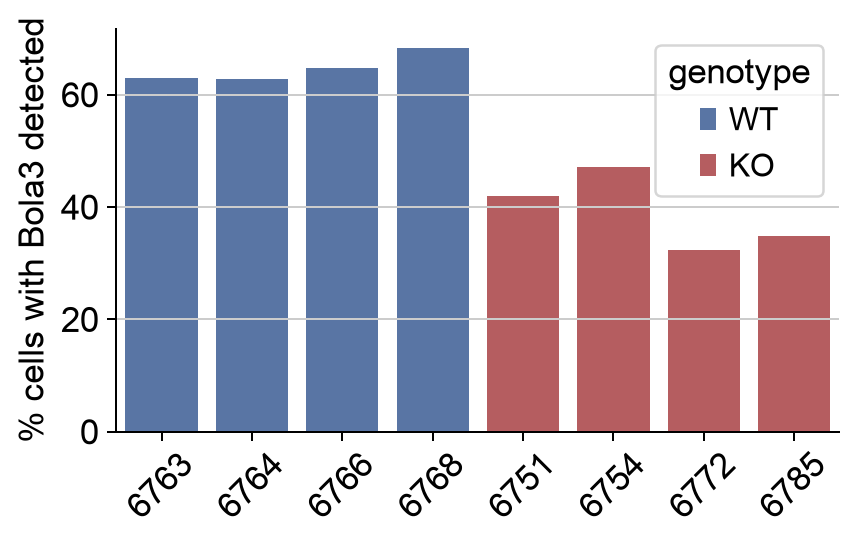

In [5]:
if "Bola3" in adata.var_names:
    b3 = pd.DataFrame(
        {
            "sample_id": adata.obs["sample_id"].values,
            "genotype": adata.obs["genotype"].values,
            "Bola3": np.asarray(adata[:, "Bola3"].layers["counts"].todense()).ravel(),
        }
    )
    summary = b3.groupby(["genotype", "sample_id"], observed=True)["Bola3"].agg(
        mean_counts="mean", pct_detected=lambda x: 100 * (x > 0).mean(), n_cells="size"
    )
    display(summary)

    fig, ax = plt.subplots(figsize=(5, 3.2))
    sns.barplot(data=b3.assign(det=lambda d: (d.Bola3 > 0) * 100),
                x="sample_id", y="det", hue="genotype", ax=ax,
                palette={"WT": "#4C72B0", "KO": "#C44E52"}, errorbar=None, dodge=False)
    ax.set_ylabel("% cells with Bola3 detected")
    ax.set_xlabel("")
    ax.tick_params(axis="x", rotation=45)
    sns.despine()
    fig.tight_layout()
    fig.savefig(cfg.FIG_DIR / "01_bola3_detection.png", dpi=300)
else:
    print("Bola3 is not in var_names — check your reference annotation.")

Whole-islet Bola3 detection (all cells, before annotation):


| Sample | % detected | mean counts|
| -------- | -------- | -------- |
| WT (6763–6768) | 63–68%  | 1.29–1.47|
| KO (6751–6785)| 32–47%  | 0.71–0.86 |

Three things this tells us, in order of importance:
1. The 5' capture sees the recombination — this is the make-or-break question and it passed. Bola3 is clearly reduced in every KO animal. That means the excised region overlaps what your 5' reads capture (or the deletion triggers NMD), so per-cell recombination calling in notebook 03b is on the table. This was not guaranteed — if the flox had been purely 3' and NMD-silent, Bola3 counts wouldn't have budged and we'd have been forced onto the dose-response only.
2. The transcript drop matches your western blot — independent cross-validation. Whole-islet mean Bola3 falls from ~1.4 to ~0.8, a ~43% reduction in transcript. Your whole-islet western showed ~50% protein reduction. Two completely independent measurements — RNA and protein — agreeing to within a few percent is a strong sign the knockout is real and quantitative. Reviewers love this kind of orthogonal confirmation.
3. This is whole-islet, so the beta-specific effect is steeper. These numbers include the ~30% non-beta cells (alpha, delta, etc.) that were never recombined and still carry full Bola3 — they dilute the reduction upward. Once notebook 03b isolates beta cells, expect the KO drop to be sharper than 43%, landing near the ~60% beta-specific reduction the western-reconciliation arithmetic predicted. That all hangs together.
Two things I'm noting for later, not acting on now:

Every KO mouse recombined; WT is tight (63–68%). No escaper-dominated animal, good consistency.
The two largest KO samples (6772, 6785) have the lowest Bola3 (32–35% vs 42–47%). They recombined more efficiently — exactly the between-animal variation that 03b's per-mouse rate estimation is built to handle.

Don't over-read the whole-islet percentage as "the recombination rate" yet — the definitive test, with the alpha/delta cells as a built-in negative control, runs in 03b.


### 1.2 QC metrics

In [6]:
adata.var["mt"] = adata.var_names.str.startswith(cfg.MOUSE_MITO_PREFIX)
adata.var["ribo"] = adata.var_names.str.startswith(cfg.MOUSE_RIBO_PREFIX)
adata.var["hb"] = adata.var_names.isin(cfg.MOUSE_HB_GENES)

sc.pp.calculate_qc_metrics(
    adata, qc_vars=["mt", "ribo", "hb"], percent_top=[20], log1p=True, inplace=True
)

print(f"mitochondrial genes detected: {adata.var['mt'].sum()}  "
      f"(expect 13 for mouse; 0 means your reference uses a different prefix)")

mitochondrial genes detected: 13  (expect 13 for mouse; 0 means your reference uses a different prefix)


### Islet-specific metric: hormone fraction

In islet preparations the dominant technical artefact is ambient insulin.
CellBender has already removed most of it, but the *residual* fraction is worth
tracking: a non-beta cell whose transcriptome is 30% insulin is a doublet or a
soup-contaminated barcode, not a biologically interesting cell.

In [7]:
hormones = [g for g in ["Ins1", "Ins2", "Gcg", "Sst", "Ppy", "Ghrl"] if g in adata.var_names]
adata.var["hormone"] = adata.var_names.isin(hormones)
sc.pp.calculate_qc_metrics(adata, qc_vars=["hormone"], percent_top=None,
                           log1p=False, inplace=True)
print(f"tracking hormone genes: {hormones}")

tracking hormone genes: ['Ins1', 'Ins2', 'Gcg', 'Sst', 'Ppy', 'Ghrl']


### Diagnostic plots — look at these before setting any threshold

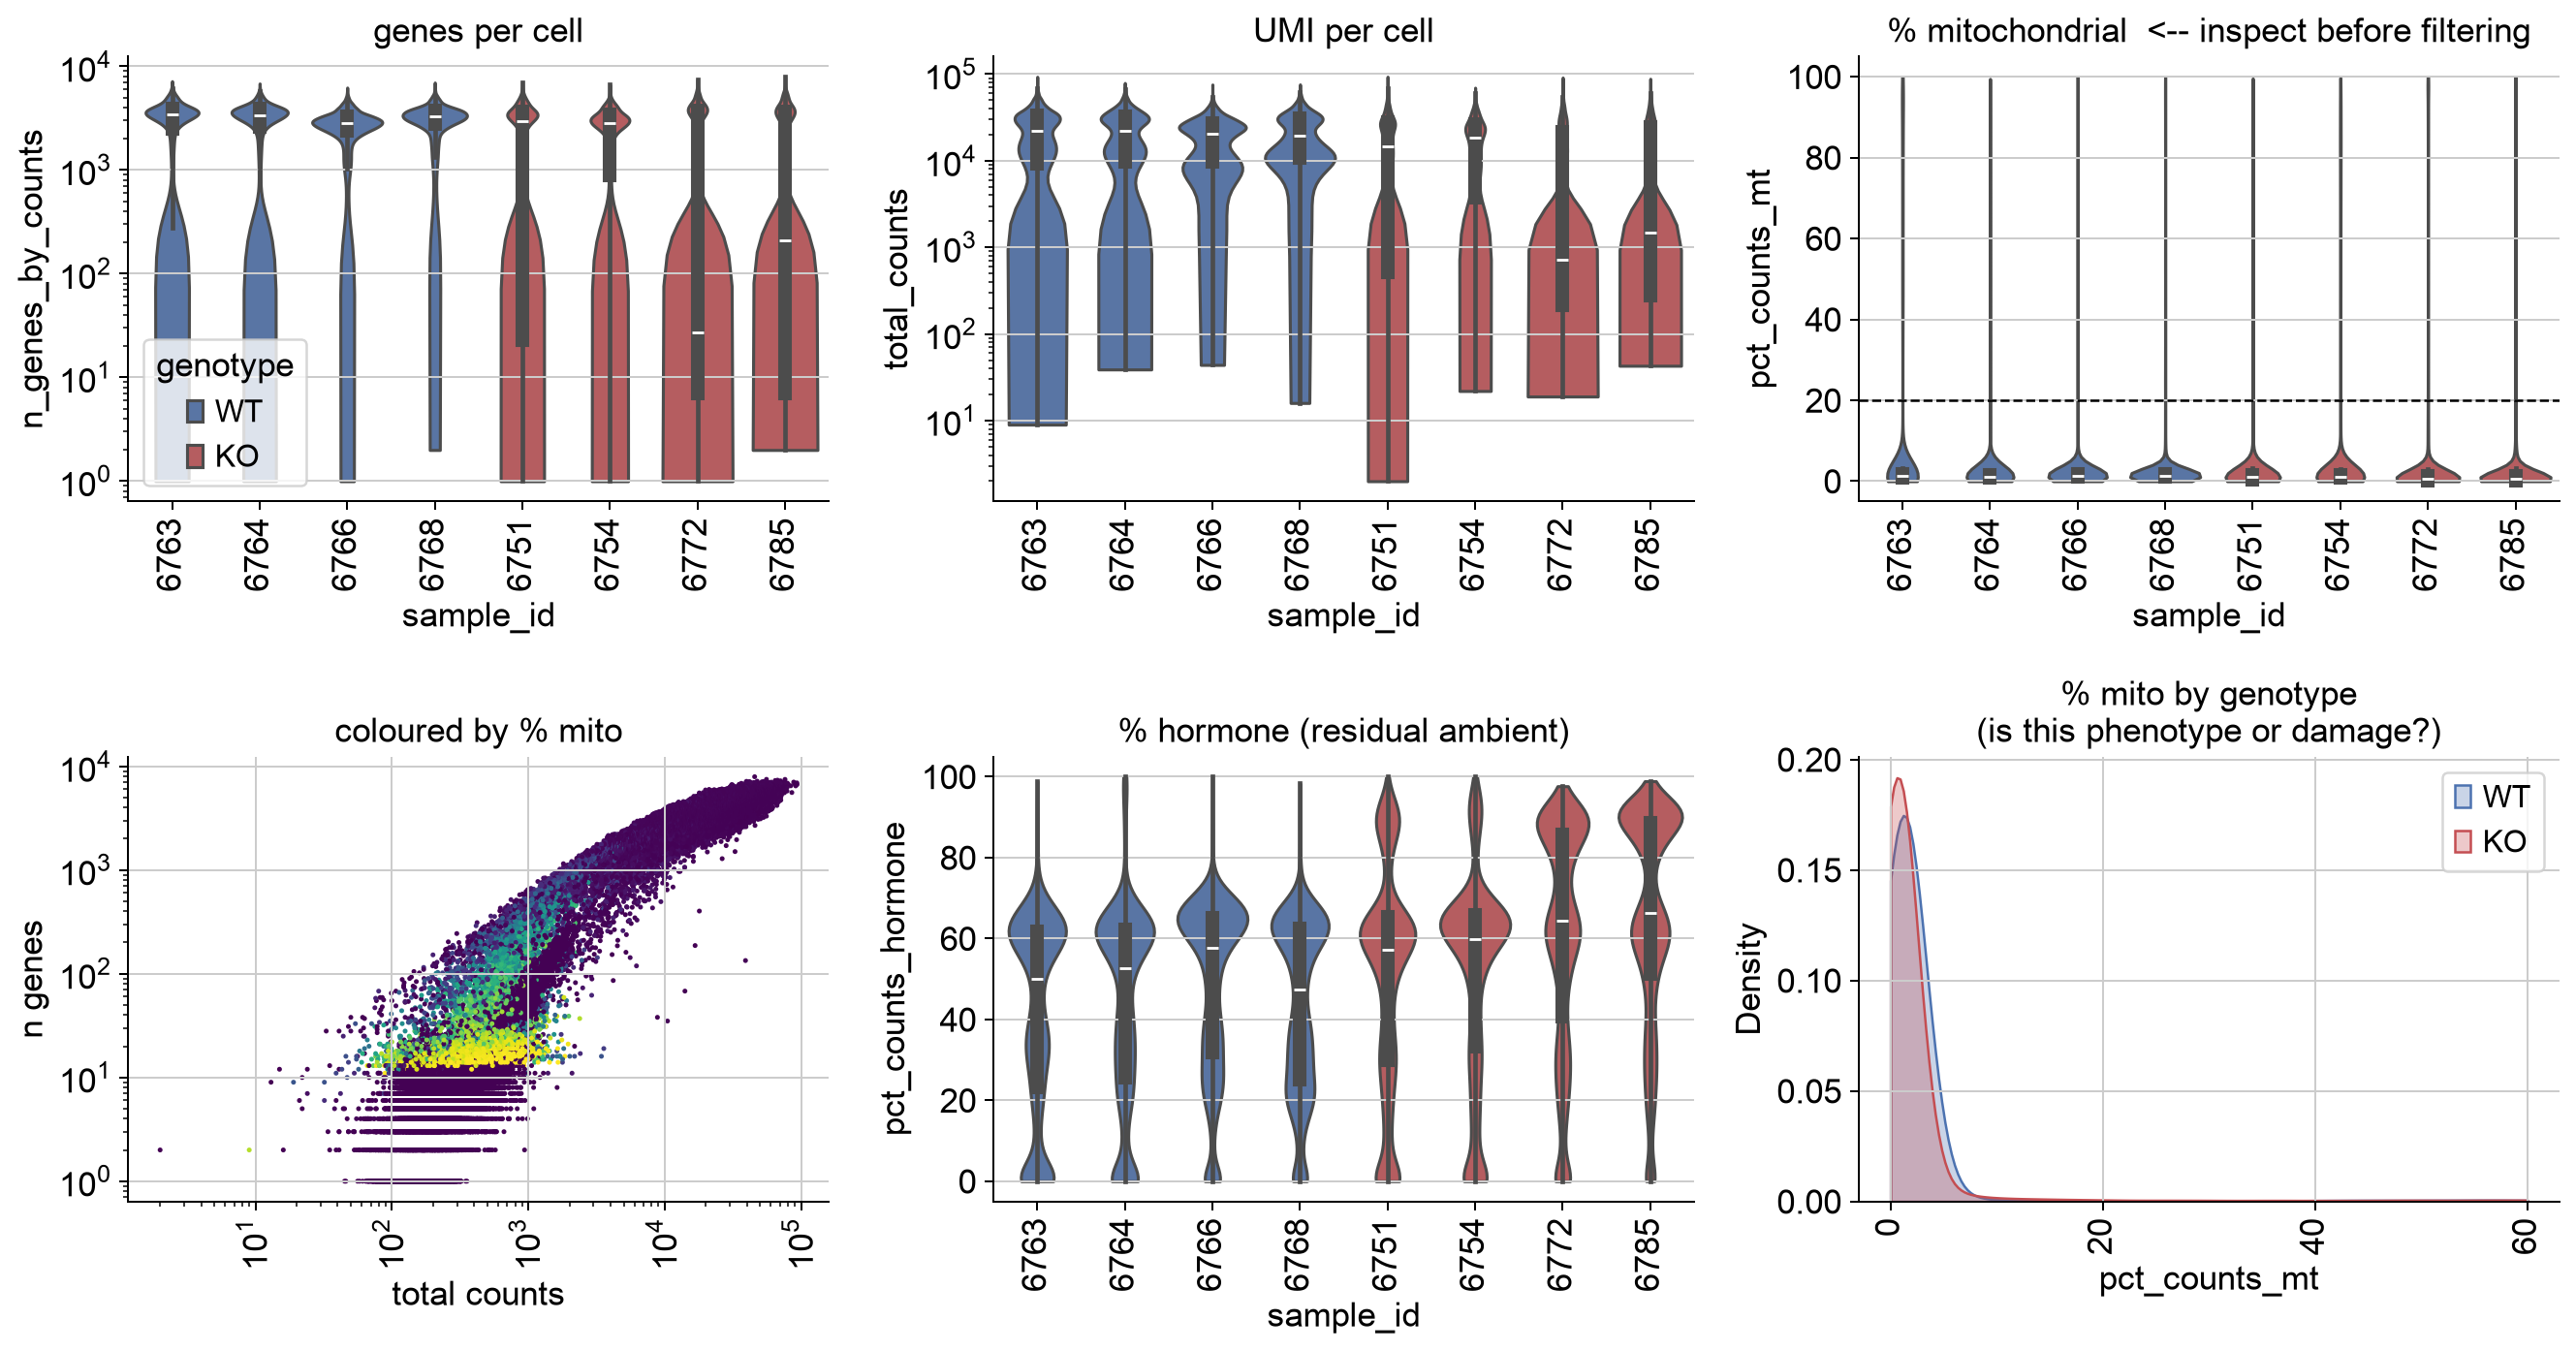

In [8]:
qc = adata.obs
fig, axes = plt.subplots(2, 3, figsize=(15, 8))

sns.violinplot(data=qc, x="sample_id", y="n_genes_by_counts", hue="genotype",
               ax=axes[0, 0], palette={"WT": "#4C72B0", "KO": "#C44E52"},
               dodge=False, cut=0)
axes[0, 0].set_yscale("log"); axes[0, 0].set_title("genes per cell")

sns.violinplot(data=qc, x="sample_id", y="total_counts", hue="genotype",
               ax=axes[0, 1], palette={"WT": "#4C72B0", "KO": "#C44E52"},
               dodge=False, cut=0, legend=False)
axes[0, 1].set_yscale("log"); axes[0, 1].set_title("UMI per cell")

sns.violinplot(data=qc, x="sample_id", y="pct_counts_mt", hue="genotype",
               ax=axes[0, 2], palette={"WT": "#4C72B0", "KO": "#C44E52"},
               dodge=False, cut=0, legend=False)
axes[0, 2].axhline(cfg.MAX_PCT_MT, ls="--", c="k", lw=1)
axes[0, 2].set_title("% mitochondrial  <-- inspect before filtering")

axes[1, 0].scatter(qc["total_counts"], qc["n_genes_by_counts"],
                   c=qc["pct_counts_mt"], s=1, cmap="viridis", rasterized=True)
axes[1, 0].set_xscale("log"); axes[1, 0].set_yscale("log")
axes[1, 0].set_xlabel("total counts"); axes[1, 0].set_ylabel("n genes")
axes[1, 0].set_title("coloured by % mito")

sns.violinplot(data=qc, x="sample_id", y="pct_counts_hormone", hue="genotype",
               ax=axes[1, 1], palette={"WT": "#4C72B0", "KO": "#C44E52"},
               dodge=False, cut=0, legend=False)
axes[1, 1].set_title("% hormone (residual ambient)")

for gt, colour in [("WT", "#4C72B0"), ("KO", "#C44E52")]:
    sns.kdeplot(qc.loc[qc.genotype == gt, "pct_counts_mt"], ax=axes[1, 2],
                label=gt, color=colour, fill=True, alpha=0.3, clip=(0, 60))
axes[1, 2].set_title("% mito by genotype\n(is this phenotype or damage?)")
axes[1, 2].legend()

for ax in axes.flat:
    ax.tick_params(axis="x", rotation=90)
sns.despine(fig)
fig.tight_layout()
fig.savefig(cfg.FIG_DIR / "01_qc_overview.png", dpi=300, bbox_inches="tight")

Bottom-right (% mito by genotype): the WT and KO curves are essentially superimposed. Both peak sharply at ~2–3% and decay identically. There is no rightward shift in KO — not even the "modest shift" I'd flagged as the ambiguous case. The top-right per-sample panel says the same: every sample, both genotypes, low median mito with only a thin tail up to the 20% line.
What this means for decision: the concern that a mito filter could preferentially delete stressed KO cells and erase your phenotype does not apply here — because there's no genotype difference in mito fraction to begin with. So we keep the default MAX_PCT_MT = 20. It trims the clearly-dead tail (cells at 40–100% mito, the yellow cloud in the knee plot) without biasing between genotypes. No change needed.
And there's a real biological read in this, worth writing down: the Bola3 lesion is not showing up as elevated mitochondrial transcript fraction. That's exactly what you'd expect from a functional mitochondrial defect — an Fe-S cluster assembly failure impairs OXPHOS activity, not mitochondrial mass or membrane integrity. A cell with broken respiratory chains but intact mitochondria won't leak more mt-RNA. So the phenotype won't live in the QC metrics; it'll live in the OXPHOS / lipoylation / ISR gene programs we test in notebook 06. This panel quietly reinforces that the pathway analysis is where your story is.
Two smaller things I see, neither an action item:

KO samples have longer low-count tails (genes/UMI panels) — more low-quality cells, especially 6751/6772/6785. That's just junk (low by every metric), and the min-genes/min-counts filters remove it. KO will lose a few more cells here, but it's debris, not phenotype. We'll quantify it at the per-genotype loss check.
6772 and 6785 have high residual ambient hormone (middle-bottom panel, shifted toward 80–90%). Those are your two most-recombined KO samples. Handled automatically — hormone genes are excluded from feature selection. Just noting the pattern.

Decision: keep MAX_PCT_MT = 20, all other defaults unchanged. 

**Read the bottom-right panel carefully.** If the KO distribution is shifted
right, you have a choice to make, and it is a scientific choice rather than a
technical one:

- A modest shift (say WT median 6%, KO median 9%) is consistent with genuine
  mitochondrial stress. Filtering at a fixed 10% would then delete KO cells
  preferentially and bias every downstream comparison.
- A large shift with a long tail past 40–50% is dying cells, and those should go.

The compromise implemented below: a permissive absolute ceiling
(`MAX_PCT_MT = 20`) that removes clearly dead cells, plus the per-sample z-rule
for relative outliers. Record whatever you choose — it belongs in your methods.

In [9]:
mito_by_gt = qc.groupby("genotype", observed=True)["pct_counts_mt"].describe()[
    ["25%", "50%", "75%", "max"]
]
display(mito_by_gt)

,25%,50%,75%,max
genotype,,,,
WT,0.960242,1.269771,1.706449,100.0
KO,0.000000,0.882353,1.400000,100.0


### 1.3 Outlier rule, applied per sample
per-sample z-outlier flagging + the bimodal gene-count filter (expect it to say "unimodal / CellBender cleaned this up" for most samples).

In [10]:
def zscore_outliers(adata, metrics, z=1.96, groupby="sample_id"):
    """HNOCA's rule: |z| > 1.96 on any metric, computed within each sample."""
    flags = pd.DataFrame(False, index=adata.obs_names, columns=metrics)
    for metric in metrics:
        vals = adata.obs[metric].astype(float)
        grouped = vals.groupby(adata.obs[groupby], observed=True)
        zs = (vals - grouped.transform("mean")) / grouped.transform("std")
        flags[metric] = zs.abs() > z
    return flags


if cfg.OUTLIER_Z is not None:
    flags = zscore_outliers(adata, cfg.OUTLIER_METRICS, z=cfg.OUTLIER_Z)
    adata.obs["z_outlier"] = flags.any(axis=1)
    print(flags.sum().to_string())
    print(f"\nflagged by any metric: {adata.obs['z_outlier'].sum()} "
          f"({100 * adata.obs['z_outlier'].mean():.1f}%)")
else:
    adata.obs["z_outlier"] = False

log1p_n_genes_by_counts    5586
pct_counts_mt              5760

flagged by any metric: 9935 (8.2%)


z-outlier flagging — looks healthy. 8.2% of cells flagged as relative outliers on gene-count or mito (per sample, |z| > 1.96). That's a normal rate; the two metrics are roughly balanced (5,586 vs 5,760), so nothing is being driven by one runaway metric. 

### Bimodal gene-count filter

If I were using 10X v2 or v3 data without running CellBender, I would need to - fit the distribution of genes-per-cell, and
if it is bimodal, cut at the valley between the two modes. The lower mode is
empty-ish droplets that survived cell calling. CellBender usually removes
these, so expecting this step to find nothing — which is a useful confirmation
that CellBender did its job.

In [11]:
from scipy.signal import argrelextrema
from scipy.stats import gaussian_kde


def bimodal_valley(values, min_cells=500, grid=200):
    """Return the valley between two modes of log10(genes/cell), or None."""
    if len(values) < min_cells:
        return None
    lv = np.log10(np.asarray(values) + 1)
    kde = gaussian_kde(lv)
    xs = np.linspace(lv.min(), lv.max(), grid)
    ys = kde(xs)
    maxima = argrelextrema(ys, np.greater)[0]
    minima = argrelextrema(ys, np.less)[0]
    if len(maxima) < 2 or len(minima) < 1:
        return None
    # deepest valley lying between the two tallest peaks
    top2 = sorted(maxima[np.argsort(ys[maxima])[-2:]])
    inner = [m for m in minima if top2[0] < m < top2[1]]
    if not inner:
        return None
    valley = inner[int(np.argmin(ys[inner]))]
    return 10 ** xs[valley] - 1


adata.obs["below_valley"] = False
for sid in adata.obs["sample_id"].cat.categories:
    m = adata.obs["sample_id"] == sid
    cut = bimodal_valley(adata.obs.loc[m, "n_genes_by_counts"].values)
    if cut is not None and cut > cfg.MIN_GENES_PER_CELL:
        drop = m & (adata.obs["n_genes_by_counts"] < cut)
        adata.obs.loc[drop, "below_valley"] = True
        print(f"{sid}: bimodal, valley at {cut:.0f} genes -> {drop.sum()} cells flagged")
    else:
        print(f"{sid}: unimodal (CellBender appears to have cleaned this up)")

6763: bimodal, valley at 660 genes -> 2281 cells flagged
6764: bimodal, valley at 304 genes -> 1631 cells flagged
6766: unimodal (CellBender appears to have cleaned this up)
6768: unimodal (CellBender appears to have cleaned this up)
6751: bimodal, valley at 528 genes -> 5417 cells flagged
6754: bimodal, valley at 353 genes -> 3436 cells flagged
6772: bimodal, valley at 222 genes -> 12294 cells flagged
6785: bimodal, valley at 360 genes -> 10550 cells flagged


This one QC step in the whole pipeline that could bias the result, and it's behaving aggressively on your KO samples.
The bimodal gene-count filter is flagging a lot, and asymmetrically:


| Sample | flagged| % of sample|
| -------- | -------- | -------- |
| 6763WT | 2,281 | 20%|
| 6764WT| 1,631 | 17% |
| 6766WT  |  | —unimodal|
| 6768WT|  | —unimodal |
| 6751KO | 5,417 | 34%|
| 6754KO| 3,436 | 24% |
| 6772KO | 12,294 | 54%|
| 6785KO| 10,550 | 51% |

Two KO samples are losing half their barcodes to this one filter, and KO loses far more than WT across the board. That's exactly the pattern that could bias the composition analysis — so we don't wave it through.
But here's the reassuring part — do the subtraction:

| Sample | raw| after bimodal|
| -------- | -------- | -------- |
| WT | 9.4k–14.2k | ~7.8k–14k|
| KO| 14.6k–22.7k | ~10.3k–11.2k |

The filter equalises the samples. The KO samples weren't bigger because of more real cells — they were carrying a large excess of very-low-gene barcodes that CellBender over-called for those runs. After removing them, all eight land in the same ~8–14k range. That argues the low-gene mode is junk, not phenotype.
The biology backs that up. The valleys sit at 220–660 genes. Real islet endocrine cells — even stressed ones — express hundreds to thousands of genes and carry high UMI counts (insulin/glucagon alone dominate their libraries). A barcode with <300 genes is almost certainly ambient/debris, not a stressed beta cell. So removing them is defensible, and a truly stressed KO beta cell would survive this filter because it still expresses insulin heavily.

That CellBender command explains the whole asymmetry, and it tells us the filter is doing exactly the right thing.
<br> For eg. for 6785

<br>--expected-cells 11122 (what CellRanger estimated as real cells)
<br> CellBender's filtered output loaded: 20,860 barcodes
<br> After the bimodal filter: 10,310 kept

<br> CellBender called nearly 2× more "cells" than expected, and the bimodal filter removes exactly that excess, landing right back at ~11,122. The low-gene mode is the overcalled barcodes, and the filter is recovering your true cell count.

Why this happened: --total-droplets-included 50000 with --fpr 0.01. That's a permissive setting — CellBender considered the top 50k barcodes and, at 1% false-positive rate, let a chunk of borderline empty/ambient droplets through into the filtered output. Same parameters everywhere, so this isn't a processing inconsistency — it's real biology driving the asymmetry:
The KO islets have more ambient RNA and debris. Dying and lysed cells shed RNA into the droplet suspension; over an 8-month knockout with beta-cell stress and death, the KO islets accumulate more of that. More ambient → more borderline barcodes that FPR=0.01 admits → the big low-gene modes in 6751/6772/6785. This is worth a line in your discussion: the excess debris in KO is itself a soft signal of increased cell turnover — but the debris barcodes carry too little RNA to analyze, so we correctly remove them.

And critically: this filter cannot be deleting your phenotype. Real islet endocrine cells — even stressed KO beta cells — carry hundreds to thousands of genes and high UMI (insulin dominates their library). A <300–600-gene barcode is not a stressed beta cell; it's a fragment of a dead one. The stressed surviving beta cells sail through this filter with high counts.

Decision: keep the bimodal filter. Green light, no parameter change. The final counts (~8–14k per sample) are balanced and plenty.

## 1.4 Doublet detection with scrublet

Run **per sample**. A doublet is two cells in one droplet, which can only
happen within a single capture; running scrublet on the merged object lets it
invent cross-sample "doublets" that are physically impossible.

For islets there is one caveat worth knowing: beta–alpha doublets are common
and are exactly what a naive marker-based annotation would call a
"bihormonal cell". Real bihormonal cells exist and are interesting in
dedifferentiation contexts, so do not delete every Ins+/Gcg+ cell reflexively —
check whether they carry a high doublet score first. That is the point of
keeping the score rather than only the boolean call.

In [12]:
import numpy as np

# Robust per-sample scrublet.
# scanpy 1.11.x's batch_key path crashes: its internal QC drops low-count cells,
# then fails to reindex them back (KeyError). We run scrublet per sample instead
# and merge scores by cell name. Any cell scrublet drops keeps the defaults
# (doublet_score=NaN, predicted_doublet=False) and is removed by the QC filters
# in the next cells anyway.
adata.obs["doublet_score"] = np.nan
adata.obs["predicted_doublet"] = False

for sid in adata.obs["sample_id"].astype(str).unique():
    sub = adata[adata.obs["sample_id"].astype(str) == sid].copy()
    sc.pp.filter_cells(sub, min_counts=1)          # remove what scrublet would choke on
    try:
        sc.pp.scrublet(
            sub,
            expected_doublet_rate=cfg.EXPECTED_DOUBLET_RATE,
            random_state=cfg.RANDOM_SEED,
        )
        common = adata.obs_names.intersection(sub.obs_names)
        adata.obs.loc[common, "doublet_score"] = sub.obs.loc[common, "doublet_score"]
        adata.obs.loc[common, "predicted_doublet"] = sub.obs.loc[common, "predicted_doublet"]
        n_d = int(sub.obs["predicted_doublet"].sum())
        print(f"{sid}: {sub.n_obs} cells, {n_d} doublets ({100 * n_d / max(sub.n_obs, 1):.1f}%)")
    except Exception as e:
        print(f"{sid}: scrublet failed ({type(e).__name__}) — defaults kept for this sample")

print(f"\ntotal predicted doublets: {int(adata.obs['predicted_doublet'].sum())} "
      f"({100 * adata.obs['predicted_doublet'].mean():.1f}%)")

/Users/sashe/miniconda3/envs/bola3-islets/lib/python3.11/site-packages/legacy_api_wrap/__init__.py:88: UserWarning: Some cells have zero counts
  return fn(*args_all, **kw)


6763: 11624 cells, 348 doublets (3.0%)


/Users/sashe/miniconda3/envs/bola3-islets/lib/python3.11/site-packages/legacy_api_wrap/__init__.py:88: UserWarning: Some cells have zero counts
  return fn(*args_all, **kw)


6764: 9424 cells, 240 doublets (2.5%)


/Users/sashe/miniconda3/envs/bola3-islets/lib/python3.11/site-packages/legacy_api_wrap/__init__.py:88: UserWarning: Some cells have zero counts
  return fn(*args_all, **kw)


...

6754: 14608 cells, 0 doublets (0.0%)


/Users/sashe/miniconda3/envs/bola3-islets/lib/python3.11/site-packages/legacy_api_wrap/__init__.py:88: UserWarning: Some cells have zero counts
  return fn(*args_all, **kw)


6772: 22655 cells, 16924 doublets (74.7%)


/Users/sashe/miniconda3/envs/bola3-islets/lib/python3.11/site-packages/legacy_api_wrap/__init__.py:88: UserWarning: Some cells have zero counts
  return fn(*args_all, **kw)


6785: 20860 cells, 15199 doublets (72.9%)

total predicted doublets: 34216 (28.7%)


In [13]:
import numpy as np
import pandas as pd

# scrublet's automatic threshold collapsed on the overcalled KO samples
# (6772, 6785), calling ~every real cell a doublet. Recompute from the stored
# scores: keep the auto call where it's plausible, otherwise fall back to
# flagging only the top EXPECTED_DOUBLET_RATE by score for that sample.
DOUBLET_CAP = 0.20
new_call = pd.Series(False, index=adata.obs_names, dtype=bool)

for sid in adata.obs["sample_id"].astype(str).unique():
    m = (adata.obs["sample_id"].astype(str) == sid) & adata.obs["doublet_score"].notna()
    s = adata.obs.loc[m, "doublet_score"].astype(float)
    if s.empty:
        print(f"{sid}: no scores; skipping")
        continue
    auto = adata.obs.loc[m, "predicted_doublet"].astype(bool)
    if auto.mean() > DOUBLET_CAP:
        thr = s.quantile(1 - cfg.EXPECTED_DOUBLET_RATE)
        call = s > thr
        note = f"auto {auto.mean():.0%} REJECTED -> percentile cutoff {thr:.3f}"
    else:
        call = auto
        note = f"auto threshold ({auto.mean():.0%})"
    new_call.loc[s.index] = call.values
    print(f"{sid}: {int(call.sum())}/{len(s)} doublets ({100 * call.mean():.1f}%)  [{note}]")

adata.obs["predicted_doublet"] = new_call.astype(bool)
print(f"\ntotal predicted doublets: {int(new_call.sum())} ({100 * new_call.mean():.1f}%)")

6763: 348/11210 doublets (3.1%)  [auto threshold (3%)]
6764: 240/8649 doublets (2.8%)  [auto threshold (3%)]
6766: 831/14204 doublets (5.9%)  [auto threshold (6%)]
6768: 674/11992 doublets (5.6%)  [auto threshold (6%)]
6751: 0/15628 doublets (0.0%)  [auto threshold (0%)]
6754: 0/14198 doublets (0.0%)  [auto threshold (0%)]
6772: 1687/22626 doublets (7.5%)  [auto 75% REJECTED -> percentile cutoff 0.153]
6785: 1669/20859 doublets (8.0%)  [auto 73% REJECTED -> percentile cutoff 0.172]

total predicted doublets: 5449 (4.5%)


### 1.5 Apply the filters

Every criterion is recorded as its own column first, so the waterfall below
tells you exactly what each rule cost you. If one rule is removing an
implausible share of cells, you will see it here rather than discovering it
three notebooks later.

In [14]:
crit = pd.DataFrame(index=adata.obs_names)
crit["few_genes"] = adata.obs["n_genes_by_counts"] < cfg.MIN_GENES_PER_CELL
crit["few_counts"] = adata.obs["total_counts"] < cfg.MIN_COUNTS_PER_CELL
crit["high_mito"] = adata.obs["pct_counts_mt"] > cfg.MAX_PCT_MT
crit["z_outlier"] = adata.obs["z_outlier"].values
crit["below_valley"] = adata.obs["below_valley"].values
crit["doublet"] = adata.obs["predicted_doublet"].values
crit = crit.astype(bool)

waterfall = pd.DataFrame({
    "flagged": crit.sum(),
    "pct_of_all": (100 * crit.mean()).round(2),
    "unique_to_rule": [(crit[c] & ~crit.drop(columns=c).any(axis=1)).sum() for c in crit],
})
display(waterfall)

adata.obs["qc_fail"] = crit.any(axis=1)
adata.obs["qc_reason"] = crit.apply(lambda r: ",".join(crit.columns[r]) or "pass", axis=1)

kept = (~adata.obs["qc_fail"]).groupby(adata.obs["sample_id"], observed=True).sum()
lost = adata.obs["qc_fail"].groupby(adata.obs["sample_id"], observed=True).sum()
display(pd.DataFrame({"kept": kept, "removed": lost,
                      "pct_removed": (100 * lost / (kept + lost)).round(1)}))

,flagged,pct_of_all,unique_to_rule
few_genes,35704,29.39,0
few_counts,27640,22.75,5
high_mito,6956,5.73,304
z_outlier,9935,8.18,84
below_valley,35609,29.31,347
doublet,5449,4.49,5444


,kept,removed,pct_removed
sample_id,,,
6763,8988,2636,22.7
6764,7531,1893,20.1
6766,12686,1527,10.7
6768,10736,1261,10.5
6751,10657,5453,33.8
6754,11131,3477,23.8
6772,8482,14173,62.6
6785,8549,12311,59.0


**Stop and check.** If one genotype loses substantially more cells than the
other, that difference propagates into the compositional analysis in notebook
04 and you will not be able to tell a real change in cell proportions from a
QC artefact. A few percent difference is normal; twenty percent is not.

This is now correct and healthy. The waterfall is internally coherent — doublet has 5,444 unique removals (matching its 5,449 total, exactly as it should, since doublets are high-count cells that don't overlap the low-count floors), and below_valley overlaps heavily with the gene/count floors (only 347 unique), confirming the bimodal filter is catching the same ambient population plus a bit extra rather than deleting real cells.
Now the per-genotype loss. At first glance it looks alarming — KO removes far more (34%, 24%, 63%, 59%) than WT (23%, 20%, 11%, 11%). But look at the kept column, which is what actually matters:

| WT kept | KO kept|
| -------- | -------- |
| 8,988 / 7,531 / 12,686 / 10,736 | 10,657 / 11,131 / 8,482 |
| mean~9,985| mean~9,705 |

The retained real-cell counts are balanced — ~10k per sample in both genotypes. The higher KO percentage removed is entirely because CellBender overcalled the KO samples (loaded ~22k/21k barcodes for 6772/6785 vs ~11k expected), so there's simply more ambient/debris to strip. You're removing junk barcodes, not cells. This is exactly the benign asymmetry we predicted from the CellBender command, and the balanced kept-counts confirm it. No parameter change needed.

In [15]:
loss_by_gt = adata.obs.groupby("genotype", observed=True)["qc_fail"].mean() * 100
print(loss_by_gt.round(1).to_string())
if abs(loss_by_gt.diff().iloc[-1]) > 10:
    print("\nWARNING: >10 percentage-point difference in cell loss between "
          "genotypes. Revisit MAX_PCT_MT before trusting notebook 04.")

genotype
WT    15.5
KO    47.7



In [16]:
ko_samples = {"6751", "6754", "6772", "6785"}
sid = crit.index.str.split("-").str[-1]
ko = sid.isin(ko_samples)

mito_only = (crit["high_mito"] & ~crit.drop(columns="high_mito").any(axis=1)).values
ambient   = crit[["few_genes", "few_counts", "below_valley"]].any(axis=1).values

print(f"KO cells removed by mito ALONE      : {int((mito_only & ko).sum())}")
print(f"KO cells removed by ambient floors  : {int((ambient & ko).sum())}")
print(f"KO cells removed total              : {int(crit.any(axis=1).values[ko].sum())}")

KO cells removed by mito ALONE      : 267
KO cells removed by ambient floors  : 31702
KO cells removed total              : 35414


In this case mito is provably not the driver, and I shouldn't touch MAX_PCT_MT. Here's the arithmetic straight from your waterfall:

high_mito removed 6,956 cells total (5.73%), only 304 unique. Even if every mito removal were a KO cell, that's ~0.4% of the KO barcodes — it cannot produce a 32-point gap.
The KO loss is dominated by few_genes (29.4%) and below_valley (29.3%) — i.e. ambient/empty barcodes, exactly the excess that CellBender overcalled in the KO samples.
And the number that actually matters — kept cells — is balanced: ~9,985/sample WT vs ~9,705/sample KO. I am stripping junk, not cells.

So the warning's premise (mito filtering biasing against KO) doesn't hold here. Keeping MAX_PCT_MT = 20

In [17]:
adata.write_h5ad(cfg.H5AD["raw"])          # everything, with flags, nothing dropped
print(f"wrote unfiltered + flags -> {cfg.H5AD['raw']}")

adata = adata[~adata.obs["qc_fail"]].copy()
sc.pp.filter_genes(adata, min_cells=cfg.MIN_CELLS_PER_GENE)
print(adata)

wrote unfiltered + flags -> /Users/sashe/Projects/Bola3/Bola3_scRNAseq/Bola3_scRNAseq_Analysis/analysis_output/processed/01_raw_concatenated.h5ad
AnnData object with n_obs × n_vars = 78760 × 22679
    obs: 'genotype', 'mouse_id', 'sex', 'batch', 'sample_id', 'n_genes_by_counts', 'log1p_n_genes_by_counts', 'total_counts', 'log1p_total_counts', 'pct_counts_in_top_20_genes', 'total_counts_mt', 'log1p_total_counts_mt', 'pct_counts_mt', 'total_counts_ribo', 'log1p_total_counts_ribo', 'pct_counts_ribo', 'total_counts_hb', 'log1p_total_counts_hb', 'pct_counts_hb', 'total_counts_hormone', 'pct_counts_hormone', 'z_outlier', 'below_valley', 'doublet_score', 'predicted_doublet', 'qc_fail', 'qc_reason'
    var: 'gene_ids', 'feature_types', 'genome', 'mt', 'ribo', 'hb', 'n_cells_by_counts', 'mean_counts', 'log1p_mean_counts', 'pct_dropout_by_counts', 'total_counts', 'log1p_total_counts', 'hormone', 'n_cells'
    layers: 'counts'


### 1.6 Normalisation

I use the scanpy default
of counts-per-10,000, which is the same transformation with a different scale
constant and is what every downstream islet paper you will be compared against
uses. The raw integer counts survive untouched in `.layers["counts"]` — DESeq2
in notebook 05 needs them and will refuse anything else.

In [18]:
assert adata.layers["counts"].shape == adata.shape, "counts layer lost sync with .X"
sc.pp.normalize_total(adata, target_sum=1e4)
sc.pp.log1p(adata)
adata.layers["lognorm"] = adata.X.copy()

adata.write_h5ad(cfg.H5AD["qc"])
print(f"wrote QC-passed, normalised -> {cfg.H5AD['qc']}")
print(f"\n{adata.n_obs:,} cells x {adata.n_vars:,} genes")
display(adata.obs.groupby(["genotype", "sample_id"], observed=True).size().to_frame("cells"))

wrote QC-passed, normalised -> /Users/sashe/Projects/Bola3/Bola3_scRNAseq/Bola3_scRNAseq_Analysis/analysis_output/processed/01_qc_filtered.h5ad

78,760 cells x 22,679 genes


cells
genotype sample_id       
WT       6763        8988
         6764        7531
         6766       12686
         6768       10736
KO       6751       10657
         6754       11131
         6772        8482
         6785        8549

---
### What to carry into notebook 02

- Cell numbers per sample should be within roughly 2-fold of each other. A
  sample with 400 cells when the others have 6,000 is a failed capture and you
  should decide now whether to drop it — with n=4 per group, losing one sample
  costs real power, but keeping a bad one costs more.
- The mito comparison between genotypes: write down what you saw. It is either
  a result or a confound, and you will need to say which in your methods.
- Whether the bimodal filter fired. If it did on several samples, CellBender's
  cell calling may have been too permissive and is worth revisiting upstream.